### Mount Drive and set paths

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/MAAI 902 X 901 PROJECT/xbd"   # contains train/ test/ hold/ tier3/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Tiling functions

In [ ]:
import csv, os
from pathlib import Path
from collections import Counter
from PIL import Image


def read_manifest(csv_path):
    with open(csv_path, newline="", encoding="utf-8") as f:
        rows = list(csv.DictReader(f))
    for r in rows:
        r["x0"], r["y0"] = int(r["x0"]), int(r["y0"])
    return rows


def tile_name(row):
    return f"{row['event']}_{row['tile_id']}_p{row['part']}"


def source_paths(root, row):
    base = f"{row['event']}_{row['tile_id']}"
    d = Path(root) / row["split"]
    return (d / "images" / f"{base}_pre_disaster.png",
            d / "images" / f"{base}_post_disaster.png",
            d / "targets" / f"{base}_post_disaster_target.png")


def make_tile(roots, row, out_dir, size=512):
    """Try each root in order; crop pre, post and mask; write only if all three were read."""
    box = (row["x0"], row["y0"], row["x0"] + size, row["y0"] + size)
    last = None
    for root in roots:
        try:
            crops = [Image.open(p).crop(box) for p in source_paths(root, row)]
            break
        except FileNotFoundError as e:
            last = e
    else:
        raise last
    out = Path(out_dir) / tile_name(row)
    out.mkdir(parents=True, exist_ok=True)
    for im, name in zip(crops, ("pre.png", "post.png", "mask.png")):
        im.save(out / name)
    return out


def build_tiles(roots, rows, out_dir):
    """Skips tiles already built. Returns (done, missing)."""
    done, missing = [], []
    for r in rows:
        out = Path(out_dir) / tile_name(r)
        if (out / "mask.png").exists():
            done.append(out)
            continue
        try:
            done.append(make_tile(roots, r, out_dir))
        except FileNotFoundError as e:
            missing.append((tile_name(r), r["split"], str(e)))
    return done, missing

### Plot a tile (kept separate from the build code)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def plot_tile(tile_dir):
    d = Path(tile_dir)
    imgs = [Image.open(d / n) for n in ("pre.png", "post.png", "mask.png")]
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    for a, im, t in zip(ax, imgs, ("pre", "post", "mask")):
        a.imshow(np.array(im), cmap="viridis" if t == "mask" else None, vmin=0, vmax=4)
        a.set_title(t); a.axis("off")
    plt.show()
    print("mask values:", np.unique(np.array(imgs[2])))

### Diagnostics (What’s missing)

In [ ]:
def folder_files(root, split, sub):
    p = f"{root}/{split}/{sub}"
    return set(os.listdir(p)) if os.path.isdir(p) else set()


def diagnose(root, rows):
    have = {(s, sub): folder_files(root, s, sub)
            for s in {r["split"] for r in rows} for sub in ("images", "targets")}
    total, miss = Counter(), Counter()
    for r in rows:
        total[(r["event"], r["split"])] += 1
        for p in source_paths(root, r):
            if p.name not in have[(r["split"], p.parent.name)]:
                miss[(r["event"], r["split"], p.parent.name)] += 1
    return have, total, miss


def missing_files(root, rows):
    """Unique image files still absent from <root>/<split>/images."""
    have = {s: folder_files(root, s, "images") for s in {r["split"] for r in rows}}
    need = set()
    for r in rows:
        for p in source_paths(root, r)[:2]:
            if p.name not in have[r["split"]]:
                need.add((r["split"], p.name))
    return sorted(need)

### Build everything that is available

10148 manifest rows
5424 done, 4724 missing
Counter({'train': 3328, 'test': 1396})


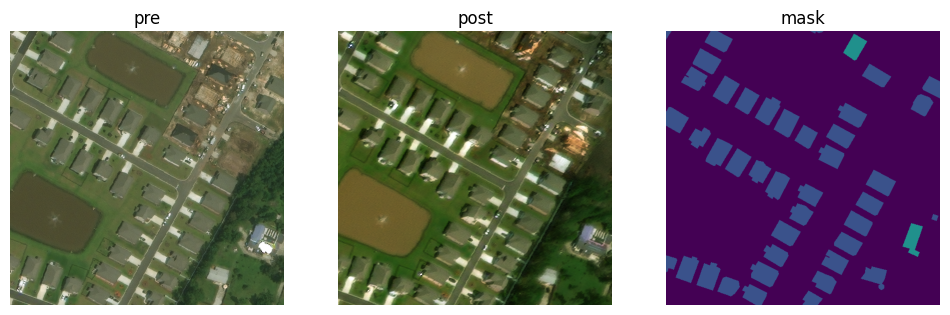

mask values: [0 1 2]


In [ ]:
rows = read_manifest(f"{ROOT}/rscc_flood_manifest.csv")
print(len(rows), "manifest rows")

done, missing = build_tiles([ROOT, NEWROOT], rows, OUT)
print(len(done), "done,", len(missing), "missing")
print(Counter(m[1] for m in missing))
plot_tile(done[0])

In [ ]:
import json
import numpy as np
from scipy import ndimage
from PIL import Image
from pathlib import Path

CLASSES = ("none", "minor", "major", "destroyed")   # mask values 1..4; 0 = background


def aggregate_grid(mask, grid=3):
    """2D mask (0 bg, 1..4 damage) -> list of grid*grid cell dicts. Each building counted once, by centre."""
    h, w = mask.shape
    counts = np.zeros((grid, grid, 4), dtype=int)
    for k in range(1, 5):
        comp, n = ndimage.label(mask == k)
        if n == 0:
            continue
        for y, x in ndimage.center_of_mass(mask == k, comp, range(1, n + 1)):
            counts[min(int(y * grid / h), grid - 1), min(int(x * grid / w), grid - 1), k - 1] += 1
    cells = []
    for r in range(grid):
        for c in range(grid):
            n = int(counts[r, c].sum())
            frac = counts[r, c] / n if n else np.zeros(4)
            cells.append({"cell": f"r{r}c{c}", "buildings": n,
                          "class_fraction": {k: round(float(f), 4) for k, f in zip(CLASSES, frac)},
                          "confidence": 1.0})   # ground truth, so no uncertainty
    return cells


def valid_fractions(tile_dir, grid=3):
    """Share of each grid cell with real pixels (not all-black no-data), row-major order."""
    d = Path(tile_dir)
    px = [np.array(Image.open(d / n).convert("RGB")).sum(axis=2) > 0 for n in ("pre.png", "post.png")]
    valid = px[0] & px[1]
    h, w = valid.shape
    return [round(float(valid[r * h // grid:(r + 1) * h // grid, c * w // grid:(c + 1) * w // grid].mean()), 3)
            for r in range(grid) for c in range(grid)]


def tile_to_evidence(tile_dir, source="labels", gsd_m=0.5):
    """gsd_m is a nominal value; xBD resolution varies by image."""
    d = Path(tile_dir)
    cells = aggregate_grid(np.array(Image.open(d / "mask.png")))
    for cell, v in zip(cells, valid_fractions(d)):
        cell["valid_fraction"] = v
    return {"tile_id": d.name, "source": source, "gsd_m": gsd_m, "grid": "3x3", "cells": cells}


def write_evidence(tile_dirs, out_dir):
    Path(out_dir).mkdir(parents=True, exist_ok=True)
    for d in tile_dirs:
        ev = tile_to_evidence(d)
        (Path(out_dir) / f"{ev['tile_id']}.json").write_text(json.dumps(ev, indent=2))

In [ ]:
import matplotlib.pyplot as plt


def plot_grid(tile_dir, evidence):
    """Post image with the 3x3 grid. Cells with valid_fraction < 0.5 are marked 'no data'."""
    im = np.array(Image.open(Path(tile_dir) / "post.png"))
    h, w = im.shape[:2]
    plt.figure(figsize=(6, 6)); plt.imshow(im)
    for i in (1, 2):
        plt.axvline(i * w / 3, color="w", lw=1); plt.axhline(i * h / 3, color="w", lw=1)
    for c in evidence["cells"]:
        r, col = int(c["cell"][1]), int(c["cell"][3])
        no_data = c.get("valid_fraction", 1.0) < 0.5
        plt.text((col + 0.5) * w / 3, (r + 0.5) * h / 3,
                 "no data" if no_data else str(c["buildings"]),
                 color="red" if no_data else "yellow",
                 ha="center", va="center", fontsize=12 if no_data else 16, weight="bold")
    plt.axis("off"); plt.show()

### Check one tile by eye, then write 20 samples. Pick tiles that actually have damage, so the checker has something to test:

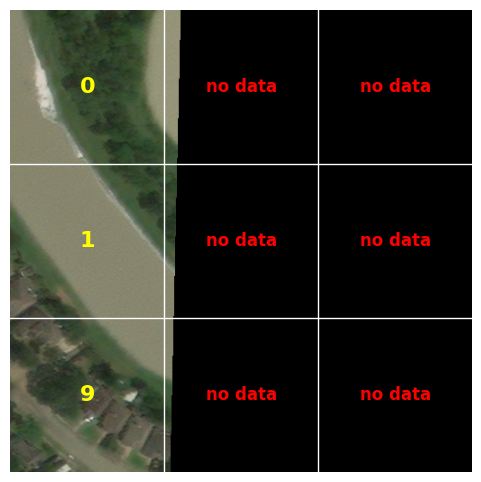

In [ ]:
import random

random.seed(0)
candidates = []
for d in done[:300]:
    ev = tile_to_evidence(d)
    dmg = sum(c["buildings"] * (1 - c["class_fraction"]["none"]) for c in ev["cells"])
    if dmg >= 3:
        candidates.append(d)
samples = random.sample(candidates, 20)
plot_grid(samples[0], tile_to_evidence(samples[0]))
write_evidence(samples, "/content/evidence_samples")
!cd /content && zip -qr evidence_samples.zip evidence_samples

In [ ]:
ev = tile_to_evidence(samples[0])
print([c["valid_fraction"] for c in ev["cells"]])

[1.0, 0.088, 0.0, 1.0, 0.066, 0.0, 1.0, 0.043, 0.0]


### Check the 20 files are clean. Clear out the output folder first, in case the earlier run left files from a different random sample, then rewrite and verify:

In [ ]:
import shutil

shutil.rmtree("/content/evidence_samples", ignore_errors=True)
write_evidence(samples, "/content/evidence_samples")

paths = sorted(Path("/content/evidence_samples").glob("*.json"))
print(len(paths), "files")
print("all cells have valid_fraction:",
      all("valid_fraction" in c for p in paths for c in json.loads(p.read_text())["cells"]))

20 files
all cells have valid_fraction: True


### Zip and download.

In [ ]:
!rm -f /content/evidence_samples.zip
!cd /content && zip -qr evidence_samples.zip evidence_samples

from google.colab import files
files.download("/content/evidence_samples.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil

dest = f"{ROOT}/processed/evidence_samples"
shutil.copytree("/content/evidence_samples", dest, dirs_exist_ok=True)
print(len(list(Path(dest).glob("*.json"))), "files in", dest)

20 files in /content/drive/MyDrive/MAAI 902 X 901 PROJECT/xbd/processed/evidence_samples


In [ ]:
def write_tile_index(done, rows, out_csv):
    by_name = {tile_name(r): r for r in rows}
    with open(out_csv, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["tile_id", "event", "xbd_split", "part"])
        for d in done:
            r = by_name[d.name]
            w.writerow([d.name, r["event"], r["split"], r["part"]])

done, missing = build_tiles([ROOT, NEWROOT], rows, OUT)   # picks up any newly uploaded images
write_tile_index(done, rows, f"{OUT}/tiles.csv")
print(len(done), "tiles indexed")

5424 tiles indexed


### Evidence for every built tile

In [ ]:
rows = read_manifest(f"{ROOT}/rscc_flood_manifest.csv")
done, missing = build_tiles([ROOT, NEWROOT], rows, OUT)
print(len(done), "tiles built,", len(missing), "still missing")
print(Counter(m[1] for m in missing))
write_tile_index(done, rows, f"{OUT}/tiles.csv")

5424 tiles built, 4724 still missing
Counter({'train': 3328, 'test': 1396})
